# Método CASTLE · Notebook 2: Simulación, Tamaño y Libre de sesgos
**Castle Quant** — De la predicción del modelo a una estrategia: entrada y salida, tamaño de la operación, apalancamiento y pruebas de sesgos.

In [1]:
# signal = model(x)
# orders = strategy(signal)
# execute(orders)

In [2]:
# En el Notebook 1 (C · Captura y A · Alfa) construimos un modelo que predice el retorno logarítmico futuro.

In [3]:
# En este notebook usamos sus predicciones para construir una estrategia y comprobar si la ventaja es real:
# S · Simulación      -> ¿sobrevive a las comisiones?
# T · Tamaño          -> ¿cuánto operar y con cuánto apalancamiento?
# L · Libre de sesgos -> ¿la ventaja es real o es un espejismo?

In [4]:
# El modelo usa los rezagos 1 y 3 de las velas de 12 horas. Más adelante lo vemos en detalle.

### Tipos de Estrategia

In [5]:
# 1 Estrategias maker => proveen liquidez => agregan liquidez al mercado y buscan ser compensadas por ello
# 2 Estrategias taker => consumen liquidez => órdenes a mercado que consumen liquidez => en estas nos vamos a enfocar

In [6]:
# Preguntas clave para nuestra estrategia taker

# 1. Entrada / Salida
# 2. Tamaño de la operación
# 3. Apalancamiento
# 4. ¿Podemos creerle al resultado?

In [7]:
## el objetivo clave es crear una estrategia que maximice las ganancias a partir de la ventaja estadística del modelo

### Importar Librerías

In [8]:
# Solo en Google Colab: trae las librerías del método, el modelo entrenado y las velas de 12 horas
import os, sys
if 'google.colab' in sys.modules and not os.path.exists('research.py'):
    !git clone --depth 1 https://github.com/JuliRey2000/metodo_CASTLE_castlequant.com.git
    %cd metodo_CASTLE_castlequant.com

In [9]:
# Librerías de datos y análisis
import polars as pl                         # DataFrames rápidos para datos financieros
import numpy as np                          # Librería de cálculo numérico

# Librerías de machine learning
import torch                                # Framework PyTorch
import research                             # Utilidades para construir, simular y probar estrategias
import models                               # El modelo lineal del Notebook 1

# Fuentes de datos
import binance                              # Comisiones de Binance Futures

pl.Config.set_tbl_cols(-1);                 # Mostrar todas las columnas sin truncar

### Cargar el Modelo

In [10]:
# El modelo predice a 12 horas: con horizontes más cortos las comisiones se comían toda la ganancia.
# Usa 2 variables: el retorno de la última vela (lag_1) y el de hace tres velas (lag_3).

In [11]:
model = models.LinearModel(2)
# alerta de seguridad: se cargan solo los pesos (weights_only=True)
model.load_state_dict(torch.load('model_weights.pth', weights_only=True))
model.eval()

LinearModel(
  (linear): Linear(in_features=2, out_features=1, bias=True)
)

### Parámetros del Modelo

In [12]:
research.print_model_params(model)

linear.weight:
[[-0.00699938  0.01524278]]
linear.bias:
[0.0002775]


### ¿Qué es la Reversión a la Media?

In [13]:
series = [-0.014000, 0.011399, -0.012212, 0.01997, -0.01442, 0.01227]
mu = np.mean(series)
mean_reversion_df = pl.DataFrame({'log_return': series, 'mean': mu})
mean_reversion_df

log_return,mean
f64,f64
-0.014,0.000501
0.011399,0.000501
-0.012212,0.000501
0.01997,0.000501
-0.01442,0.000501
0.01227,0.000501


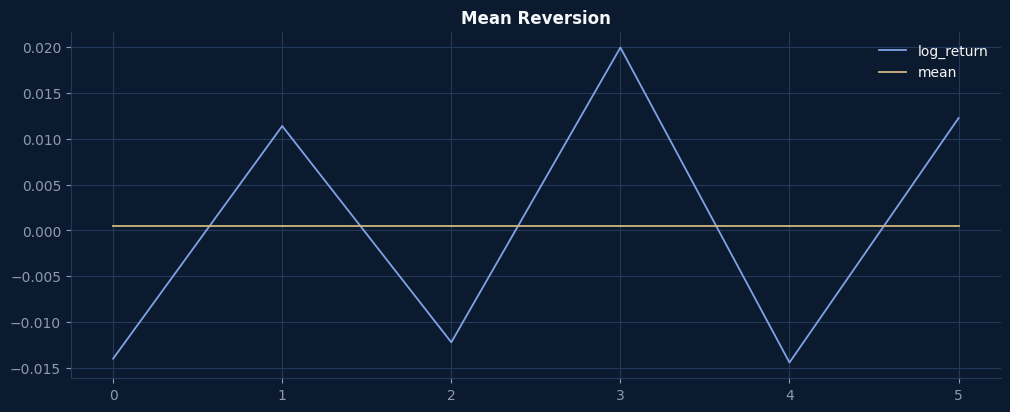

In [14]:
research.plot_multiple_lines(mean_reversion_df, ['log_return','mean'], 'Mean Reversion')

### Interpretabilidad - Modelo Lineal

In [15]:
def linear_model(x1, x3):
    w1, w3, b = -0.0070, 0.0152, 0.00028
    return w1 * x1 + w3 * x3 + b

# la última vela subió 5%: el peso negativo de lag_1 predice una devolución (reversión a la media)
linear_model(0.05, 0.0)

-7.000000000000008e-05

In [16]:
# hace tres velas el precio cayó 3%: el peso positivo de lag_3 predice que la caída continúa (momentum)
linear_model(0.0, -0.03)

-0.000176

In [17]:
# sin movimiento reciente solo queda el sesgo, que es positivo: el modelo aprendió de un mercado alcista
linear_model(0.0, 0.0)

0.00028

### Interpretabilidad - Modelo No Lineal

In [18]:
def nn_model(x):
    x = torch.tensor([x])
    W = torch.tensor([0.08035, -0.01478, -0.03523,  0.06777,  0.03789,  0.0013991, -0.13303,  0.8045])
    b = torch.tensor([0.16421])
    return torch.tanh(torch.sum(x * W) + b)

nn_model(-0.015)

tensor([0.1509])

In [19]:
# no es interpretable
nn_model(0.02)

tensor([0.1785])

In [20]:
# no se trata de desmerecer a las redes neuronales
# pero en trading las redes neuronales pueden aumentar el valor esperado a costa de más complejidad
# los modelos lineales suelen ser preferibles porque son interpretables, poco sensibles al ruido y menos propensos al sobreajuste (generalizan mejor)

## ¡Desarrollo de la Estrategia!

### Cargar la Serie de Tiempo

In [21]:
sym = 'BTCUSDT'
time_interval = '12h'

ts = pl.read_csv(f"{sym}_{time_interval}_ohlc.csv", try_parse_dates=True).sort('datetime')
ts

datetime,open,high,low,close
datetime[μs],f64,f64,f64,f64
2022-01-01 00:00:00,46210.57,47566.66,46210.55,46755.01
2022-01-01 12:00:00,46755.01,47943.77,46755.01,47704.35
2022-01-02 00:00:00,47704.35,47745.61,46749.99,47231.3
2022-01-02 12:00:00,47231.29,48000.0,46605.68,47280.0
2022-01-03 00:00:00,47280.01,47436.26,46717.26,47364.11
…,…,…,…,…
2026-10-29 12:00:00,80130.9,81953.7,77868.4,77962.6
2026-10-30 00:00:00,77962.6,78776.5,76444.0,77345.9
2026-10-30 12:00:00,77345.8,78081.3,76270.0,77312.6


### Agregar el Objetivo y las Variables

In [22]:
forecast_horizon = 1
ts = research.add_log_return_features(ts, 'close', forecast_horizon, max_no_lags=4).drop_nulls()
ts

datetime,open,high,low,close,close_log_return,close_log_return_lag_1,close_log_return_lag_2,close_log_return_lag_3,close_log_return_lag_4
datetime[μs],f64,f64,f64,f64,f64,f64,f64,f64,f64
2022-01-03 12:00:00,47364.11,47575.22,45665.4,46445.81,-0.019579,0.001777,0.001031,-0.009966,0.020101
2022-01-04 00:00:00,46445.8,46750.0,45931.61,46709.98,0.005672,-0.019579,0.001777,0.001031,-0.009966
2022-01-04 12:00:00,46709.97,47524.36,45445.57,45833.42,-0.018944,0.005672,-0.019579,0.001777,0.001031
2022-01-05 00:00:00,45833.41,47075.29,45710.23,46271.93,0.009522,-0.018944,0.005672,-0.019579,0.001777
2022-01-05 12:00:00,46271.93,46820.83,42270.0,43421.69,-0.063576,0.009522,-0.018944,0.005672,-0.019579
…,…,…,…,…,…,…,…,…,…
2026-10-29 12:00:00,80130.9,81953.7,77868.4,77962.6,-0.027432,-0.014593,0.000132,0.005298,0.012296
2026-10-30 00:00:00,77962.6,78776.5,76444.0,77345.9,-0.007942,-0.027432,-0.014593,0.000132,0.005298
2026-10-30 12:00:00,77345.8,78081.3,76270.0,77312.6,-0.000431,-0.007942,-0.027432,-0.014593,0.000132


### División Temporal

In [23]:
# la misma partición del Notebook 1: 60% entrenamiento, 20% validación, 20% prueba
# trades = dentro de muestra: la validación, el tramo con el que elegimos el modelo
# test_trades = fuera de muestra: la prueba. El modelo nunca la ha visto y queda sellada hasta la sección L
val_size, test_size = 0.2, 0.2
_, trades, test_trades = research.timeseries_split(ts, val_size, test_size)
trades

datetime,open,high,low,close,close_log_return,close_log_return_lag_1,close_log_return_lag_2,close_log_return_lag_3,close_log_return_lag_4
datetime[μs],f64,f64,f64,f64,f64,f64,f64,f64,f64
2024-11-26 00:00:00,93064.0,95064.0,91553.0,92420.0,-0.006944,-0.054411,0.003135,0.006378,-0.003977
2024-11-26 12:00:00,92420.0,94745.2,90866.4,92021.4,-0.004322,-0.006944,-0.054411,0.003135,0.006378
2024-11-27 00:00:00,92021.5,93939.0,91864.0,93423.8,0.015125,-0.004322,-0.006944,-0.054411,0.003135
2024-11-27 12:00:00,93423.8,97250.0,92903.4,95905.2,0.026214,0.015125,-0.004322,-0.006944,-0.054411
2024-11-28 00:00:00,95905.2,96627.6,94700.1,95509.9,-0.00413,0.026214,0.015125,-0.004322,-0.006944
…,…,…,…,…,…,…,…,…,…
2025-11-11 00:00:00,105966.3,107473.7,104685.3,105256.2,-0.006724,-0.001606,0.013909,0.023904,-0.000695
2025-11-11 12:00:00,105256.2,105459.8,102400.0,103005.8,-0.021612,-0.006724,-0.001606,0.013909,0.023904
2025-11-12 00:00:00,103005.8,105162.6,102629.5,104979.9,0.018984,-0.021612,-0.006724,-0.001606,0.013909


---
# S · Simulación
## Decisión de Estrategia #1: Señal de Entrada / Salida

In [24]:
# p1: ¿cuándo entramos? señal de entrada
# p2: ¿cuándo salimos? señal de salida

In [25]:
# 1. Basada en tiempo
# 2. Basada en una condición

In [26]:
# ejemplo de condición => solo operamos si y_hat está por encima o por debajo de cierto umbral

In [27]:
# basada en tiempo => cada 12 horas, al cerrar la vela, el modelo decide la dirección de la vela siguiente.
# si la dirección cambia, se cierra la posición y se abre la contraria (2 operaciones); si no cambia, se mantiene (0 operaciones)

### Agregar las Predicciones del Modelo

In [28]:
target = 'close_log_return'
features = [f'{target}_lag_1', f'{target}_lag_3']
trades = research.add_model_predictions(trades, model, features)
trades

datetime,open,high,low,close,close_log_return,close_log_return_lag_1,close_log_return_lag_2,close_log_return_lag_3,close_log_return_lag_4,y_hat
datetime[μs],f64,f64,f64,f64,f64,f64,f64,f64,f64,f64
2024-11-26 00:00:00,93064.0,95064.0,91553.0,92420.0,-0.006944,-0.054411,0.003135,0.006378,-0.003977,0.000756
2024-11-26 12:00:00,92420.0,94745.2,90866.4,92021.4,-0.004322,-0.006944,-0.054411,0.003135,0.006378,0.000374
2024-11-27 00:00:00,92021.5,93939.0,91864.0,93423.8,0.015125,-0.004322,-0.006944,-0.054411,0.003135,-0.000522
2024-11-27 12:00:00,93423.8,97250.0,92903.4,95905.2,0.026214,0.015125,-0.004322,-0.006944,-0.054411,0.000066
2024-11-28 00:00:00,95905.2,96627.6,94700.1,95509.9,-0.00413,0.026214,0.015125,-0.004322,-0.006944,0.000028
…,…,…,…,…,…,…,…,…,…,…
2025-11-11 00:00:00,105966.3,107473.7,104685.3,105256.2,-0.006724,-0.001606,0.013909,0.023904,-0.000695,0.000653
2025-11-11 12:00:00,105256.2,105459.8,102400.0,103005.8,-0.021612,-0.006724,-0.001606,0.013909,0.023904,0.000537
2025-11-12 00:00:00,103005.8,105162.6,102629.5,104979.9,0.018984,-0.021612,-0.006724,-0.001606,0.013909,0.000404


### Agregar la Señal Direccional

In [29]:
trades = trades.with_columns(pl.col('y_hat').sign().alias('dir_signal'))
trades

datetime,open,high,low,close,close_log_return,close_log_return_lag_1,close_log_return_lag_2,close_log_return_lag_3,close_log_return_lag_4,y_hat,dir_signal
datetime[μs],f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64
2024-11-26 00:00:00,93064.0,95064.0,91553.0,92420.0,-0.006944,-0.054411,0.003135,0.006378,-0.003977,0.000756,1.0
2024-11-26 12:00:00,92420.0,94745.2,90866.4,92021.4,-0.004322,-0.006944,-0.054411,0.003135,0.006378,0.000374,1.0
2024-11-27 00:00:00,92021.5,93939.0,91864.0,93423.8,0.015125,-0.004322,-0.006944,-0.054411,0.003135,-0.000522,-1.0
2024-11-27 12:00:00,93423.8,97250.0,92903.4,95905.2,0.026214,0.015125,-0.004322,-0.006944,-0.054411,0.000066,1.0
2024-11-28 00:00:00,95905.2,96627.6,94700.1,95509.9,-0.00413,0.026214,0.015125,-0.004322,-0.006944,0.000028,1.0
…,…,…,…,…,…,…,…,…,…,…,…
2025-11-11 00:00:00,105966.3,107473.7,104685.3,105256.2,-0.006724,-0.001606,0.013909,0.023904,-0.000695,0.000653,1.0
2025-11-11 12:00:00,105256.2,105459.8,102400.0,103005.8,-0.021612,-0.006724,-0.001606,0.013909,0.023904,0.000537,1.0
2025-11-12 00:00:00,103005.8,105162.6,102629.5,104979.9,0.018984,-0.021612,-0.006724,-0.001606,0.013909,0.000404,1.0


### Calcular el Retorno Logarítmico de la Operación

In [30]:
trades = trades.with_columns((pl.col('close_log_return')*pl.col('dir_signal')).alias('trade_log_return'))
trades

datetime,open,high,low,close,close_log_return,close_log_return_lag_1,close_log_return_lag_2,close_log_return_lag_3,close_log_return_lag_4,y_hat,dir_signal,trade_log_return
datetime[μs],f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64
2024-11-26 00:00:00,93064.0,95064.0,91553.0,92420.0,-0.006944,-0.054411,0.003135,0.006378,-0.003977,0.000756,1.0,-0.006944
2024-11-26 12:00:00,92420.0,94745.2,90866.4,92021.4,-0.004322,-0.006944,-0.054411,0.003135,0.006378,0.000374,1.0,-0.004322
2024-11-27 00:00:00,92021.5,93939.0,91864.0,93423.8,0.015125,-0.004322,-0.006944,-0.054411,0.003135,-0.000522,-1.0,-0.015125
2024-11-27 12:00:00,93423.8,97250.0,92903.4,95905.2,0.026214,0.015125,-0.004322,-0.006944,-0.054411,0.000066,1.0,0.026214
2024-11-28 00:00:00,95905.2,96627.6,94700.1,95509.9,-0.00413,0.026214,0.015125,-0.004322,-0.006944,0.000028,1.0,-0.00413
…,…,…,…,…,…,…,…,…,…,…,…,…
2025-11-11 00:00:00,105966.3,107473.7,104685.3,105256.2,-0.006724,-0.001606,0.013909,0.023904,-0.000695,0.000653,1.0,-0.006724
2025-11-11 12:00:00,105256.2,105459.8,102400.0,103005.8,-0.021612,-0.006724,-0.001606,0.013909,0.023904,0.000537,1.0,-0.021612
2025-11-12 00:00:00,103005.8,105162.6,102629.5,104979.9,0.018984,-0.021612,-0.006724,-0.001606,0.013909,0.000404,1.0,0.018984


### Calcular el Retorno Logarítmico Acumulado

In [31]:
trades = trades.with_columns(pl.col('trade_log_return').cum_sum().alias('cum_trade_log_return'))
trades

datetime,open,high,low,close,close_log_return,close_log_return_lag_1,close_log_return_lag_2,close_log_return_lag_3,close_log_return_lag_4,y_hat,dir_signal,trade_log_return,cum_trade_log_return
datetime[μs],f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64
2024-11-26 00:00:00,93064.0,95064.0,91553.0,92420.0,-0.006944,-0.054411,0.003135,0.006378,-0.003977,0.000756,1.0,-0.006944,-0.006944
2024-11-26 12:00:00,92420.0,94745.2,90866.4,92021.4,-0.004322,-0.006944,-0.054411,0.003135,0.006378,0.000374,1.0,-0.004322,-0.011266
2024-11-27 00:00:00,92021.5,93939.0,91864.0,93423.8,0.015125,-0.004322,-0.006944,-0.054411,0.003135,-0.000522,-1.0,-0.015125,-0.026391
2024-11-27 12:00:00,93423.8,97250.0,92903.4,95905.2,0.026214,0.015125,-0.004322,-0.006944,-0.054411,0.000066,1.0,0.026214,-0.000177
2024-11-28 00:00:00,95905.2,96627.6,94700.1,95509.9,-0.00413,0.026214,0.015125,-0.004322,-0.006944,0.000028,1.0,-0.00413,-0.004307
…,…,…,…,…,…,…,…,…,…,…,…,…,…
2025-11-11 00:00:00,105966.3,107473.7,104685.3,105256.2,-0.006724,-0.001606,0.013909,0.023904,-0.000695,0.000653,1.0,-0.006724,0.834791
2025-11-11 12:00:00,105256.2,105459.8,102400.0,103005.8,-0.021612,-0.006724,-0.001606,0.013909,0.023904,0.000537,1.0,-0.021612,0.813179
2025-11-12 00:00:00,103005.8,105162.6,102629.5,104979.9,0.018984,-0.021612,-0.006724,-0.001606,0.013909,0.000404,1.0,0.018984,0.832163


### Mostrar la Curva de Capital (Escala Logarítmica)

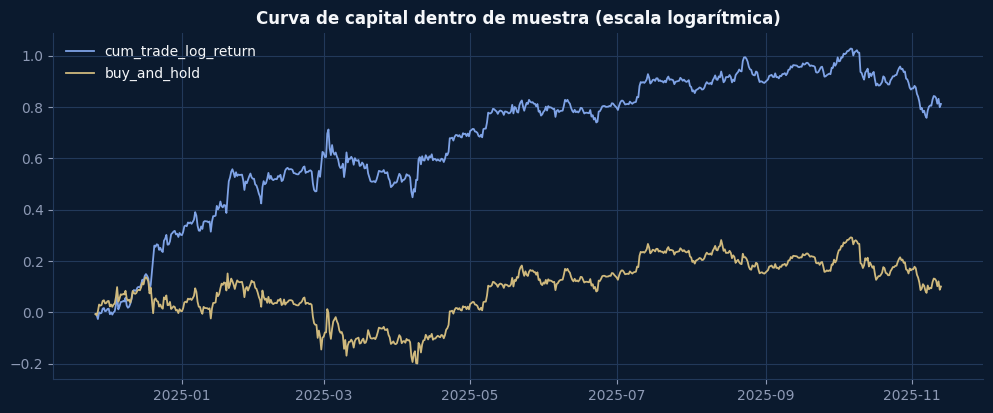

In [32]:
# la estrategia, antes de comisiones, al lado de simplemente comprar y mantener
trades = trades.with_columns(pl.col('close_log_return').cum_sum().alias('buy_and_hold'))
research.plot_multiple_lines(trades, ['cum_trade_log_return', 'buy_and_hold'], 'Curva de capital dentro de muestra (escala logarítmica)')

### Contar las Operaciones

In [33]:
# 1 operación al abrir, 2 al dar la vuelta (cerrar y abrir la contraria) y 0 si la dirección se mantiene
trades = trades.with_columns((pl.col('dir_signal') - pl.col('dir_signal').shift().fill_null(0)).abs().alias('no_trades'))
trades.select('datetime', 'y_hat', 'dir_signal', 'no_trades')

datetime,y_hat,dir_signal,no_trades
datetime[μs],f64,f64,f64
2024-11-26 00:00:00,0.000756,1.0,1.0
2024-11-26 12:00:00,0.000374,1.0,0.0
2024-11-27 00:00:00,-0.000522,-1.0,2.0
2024-11-27 12:00:00,0.000066,1.0,2.0
2024-11-28 00:00:00,0.000028,1.0,0.0
…,…,…,…
2025-11-11 00:00:00,0.000653,1.0,0.0
2025-11-11 12:00:00,0.000537,1.0,0.0
2025-11-12 00:00:00,0.000404,1.0,0.0


In [34]:
# velas en largo, velas en corto y número total de operaciones
(trades['dir_signal'] == 1).sum(), (trades['dir_signal'] == -1).sum(), trades['no_trades'].sum()

(624, 81, 273.0)

---
# T · Tamaño
## Decisión Clave de Estrategia #2: Tamaño de la Operación

In [35]:
# 1. Tamaño constante
# 2. Tamaño compuesto

In [36]:
capital = 100
ratio = 1.0 # se puede experimentar con otras proporciones, como el criterio de Kelly (más abajo)
trade_value = ratio * capital

# valor de entrada y valor de salida de la operación
trades = trades.with_columns(
    pl.lit(trade_value).alias('entry_trade_value'),
    (trade_value * pl.col('trade_log_return').exp()).alias('exit_trade_value'),
    (trade_value / pl.col('open')).alias('trade_qty'),
).with_columns(
    (pl.col('trade_qty') * pl.col('dir_signal')).alias('signed_trade_qty'),
)

trades.select('datetime','open','close', 'trade_log_return','y_hat','entry_trade_value','exit_trade_value', 'signed_trade_qty')

datetime,open,close,trade_log_return,y_hat,entry_trade_value,exit_trade_value,signed_trade_qty
datetime[μs],f64,f64,f64,f64,f64,f64,f64
2024-11-26 00:00:00,93064.0,92420.0,-0.006944,0.000756,100.0,99.308003,0.001075
2024-11-26 12:00:00,92420.0,92021.4,-0.004322,0.000374,100.0,99.568708,0.001082
2024-11-27 00:00:00,92021.5,93423.8,-0.015125,-0.000522,100.0,98.498884,-0.001087
2024-11-27 12:00:00,93423.8,95905.2,0.026214,0.000066,100.0,102.656068,0.00107
2024-11-28 00:00:00,95905.2,95509.9,-0.00413,0.000028,100.0,99.587822,0.001043
…,…,…,…,…,…,…,…
2025-11-11 00:00:00,105966.3,105256.2,-0.006724,0.000653,100.0,99.329881,0.000944
2025-11-11 12:00:00,105256.2,103005.8,-0.021612,0.000537,100.0,97.861979,0.00095
2025-11-12 00:00:00,103005.8,104979.9,0.018984,0.000404,100.0,101.916494,0.000971


### Agregar la Ganancia Bruta de la Operación (Gross PnL)

In [37]:
trades = trades.with_columns((pl.col('exit_trade_value') - pl.col('entry_trade_value')).alias('trade_gross_pnl'))
trades.select('datetime','open','close', 'trade_log_return','entry_trade_value','exit_trade_value', 'trade_gross_pnl')

datetime,open,close,trade_log_return,entry_trade_value,exit_trade_value,trade_gross_pnl
datetime[μs],f64,f64,f64,f64,f64,f64
2024-11-26 00:00:00,93064.0,92420.0,-0.006944,100.0,99.308003,-0.691997
2024-11-26 12:00:00,92420.0,92021.4,-0.004322,100.0,99.568708,-0.431292
2024-11-27 00:00:00,92021.5,93423.8,-0.015125,100.0,98.498884,-1.501116
2024-11-27 12:00:00,93423.8,95905.2,0.026214,100.0,102.656068,2.656068
2024-11-28 00:00:00,95905.2,95509.9,-0.00413,100.0,99.587822,-0.412178
…,…,…,…,…,…,…
2025-11-11 00:00:00,105966.3,105256.2,-0.006724,100.0,99.329881,-0.670119
2025-11-11 12:00:00,105256.2,103005.8,-0.021612,100.0,97.861979,-2.138021
2025-11-12 00:00:00,103005.8,104979.9,0.018984,100.0,101.916494,1.916494


### Agregar las Comisiones de Transacción

In [38]:
taker_fee = binance.TAKER_FEE
maker_fee = binance.MAKER_FEE

# la comisión se paga sobre el valor operado, y solo en las velas donde hay operaciones
trades = trades.with_columns(
    (pl.col('no_trades') * pl.col('entry_trade_value') * taker_fee).alias('taker_fee'),
    (pl.col('no_trades') * pl.col('entry_trade_value') * maker_fee).alias('maker_fee')
)

trades.select('datetime','dir_signal','no_trades','entry_trade_value','trade_gross_pnl','maker_fee','taker_fee')

datetime,dir_signal,no_trades,entry_trade_value,trade_gross_pnl,maker_fee,taker_fee
datetime[μs],f64,f64,f64,f64,f64,f64
2024-11-26 00:00:00,1.0,1.0,100.0,-0.691997,0.02,0.05
2024-11-26 12:00:00,1.0,0.0,100.0,-0.431292,0.0,0.0
2024-11-27 00:00:00,-1.0,2.0,100.0,-1.501116,0.04,0.1
2024-11-27 12:00:00,1.0,2.0,100.0,2.656068,0.04,0.1
2024-11-28 00:00:00,1.0,0.0,100.0,-0.412178,0.0,0.0
…,…,…,…,…,…,…
2025-11-11 00:00:00,1.0,0.0,100.0,-0.670119,0.0,0.0
2025-11-11 12:00:00,1.0,0.0,100.0,-2.138021,0.0,0.0
2025-11-12 00:00:00,1.0,0.0,100.0,1.916494,0.0,0.0


### Calcular la Ganancia Neta de la Operación (Net PnL)

In [39]:
trades = trades.with_columns(
    (pl.col('trade_gross_pnl')-pl.col('taker_fee')).alias('trade_net_taker_pnl'),
    (pl.col('trade_gross_pnl')-pl.col('maker_fee')).alias('trade_net_maker_pnl'),
)

trades.select('datetime','open','close', 'trade_log_return','signed_trade_qty', 'trade_gross_pnl','trade_net_taker_pnl','trade_net_maker_pnl')

datetime,open,close,trade_log_return,signed_trade_qty,trade_gross_pnl,trade_net_taker_pnl,trade_net_maker_pnl
datetime[μs],f64,f64,f64,f64,f64,f64,f64
2024-11-26 00:00:00,93064.0,92420.0,-0.006944,0.001075,-0.691997,-0.741997,-0.711997
2024-11-26 12:00:00,92420.0,92021.4,-0.004322,0.001082,-0.431292,-0.431292,-0.431292
2024-11-27 00:00:00,92021.5,93423.8,-0.015125,-0.001087,-1.501116,-1.601116,-1.541116
2024-11-27 12:00:00,93423.8,95905.2,0.026214,0.00107,2.656068,2.556068,2.616068
2024-11-28 00:00:00,95905.2,95509.9,-0.00413,0.001043,-0.412178,-0.412178,-0.412178
…,…,…,…,…,…,…,…
2025-11-11 00:00:00,105966.3,105256.2,-0.006724,0.000944,-0.670119,-0.670119,-0.670119
2025-11-11 12:00:00,105256.2,103005.8,-0.021612,0.00095,-2.138021,-2.138021,-2.138021
2025-11-12 00:00:00,103005.8,104979.9,0.018984,0.000971,1.916494,1.916494,1.916494


### Mostrar las Curvas de Capital con Tamaño Constante

In [40]:
def equity_curve(capital, col_name, suffix):
    return (capital + (pl.col(col_name).cum_sum())).alias(f'equity_curve_{suffix}')

trades = trades.with_columns(
    equity_curve(capital, 'trade_net_taker_pnl', 'taker'),
    equity_curve(capital, 'trade_net_maker_pnl', 'maker'),
    equity_curve(capital, 'trade_gross_pnl', 'gross'),
)
trades.select('datetime','equity_curve_gross','equity_curve_taker','equity_curve_maker')

datetime,equity_curve_gross,equity_curve_taker,equity_curve_maker
datetime[μs],f64,f64,f64
2024-11-26 00:00:00,99.308003,99.258003,99.288003
2024-11-26 12:00:00,98.876711,98.826711,98.856711
2024-11-27 00:00:00,97.375595,97.225595,97.315595
2024-11-27 12:00:00,100.031663,99.781663,99.931663
2024-11-28 00:00:00,99.619485,99.369485,99.519485
…,…,…,…
2025-11-11 00:00:00,193.272025,179.622025,187.812025
2025-11-11 12:00:00,191.134004,177.484004,185.674004
2025-11-12 00:00:00,193.050498,179.400498,187.590498


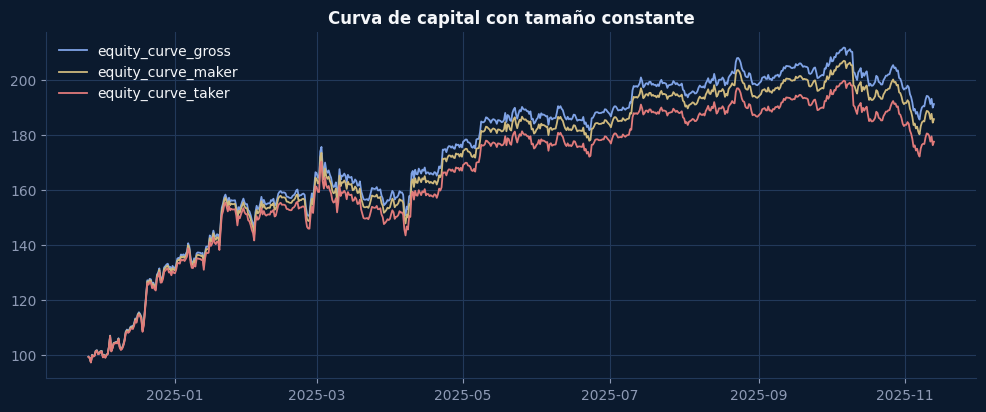

In [41]:
research.plot_multiple_lines(trades, ['equity_curve_gross', 'equity_curve_maker', 'equity_curve_taker'], 'Curva de capital con tamaño constante')

### Calcular el Retorno Neto Total con Tamaño Constante

In [42]:
constant_sizing_net_return = trades['equity_curve_taker'][-1] / capital - 1
constant_sizing_net_return

0.7746020028486504

In [43]:
# cuánto del resultado se fue en comisiones (como fracción del capital)
trades['taker_fee'].sum() / capital

0.1365

## Experimento con Tamaño Compuesto

In [44]:
# 2 => 102 (100 + 2)
# 1 => 103 (100 + 2 + 1)
# -1 => 102 (100 + 2 + 1 - 1)

In [45]:
log_return_1 = 0.005439
pnl1 = capital * np.exp(log_return_1)
pnl1

np.float64(100.54538182137402)

In [46]:
log_return_2 = 0.008597
pnl2 = pnl1 * np.exp(log_return_2)
pnl2

np.float64(101.41349671401576)

In [47]:
log_return_3 = 0.001385
pnl3 = pnl2 * np.exp(log_return_3)
pnl3

np.float64(101.55405171883751)

### Aditividad Temporal

In [48]:
capital * np.exp(log_return_1 + log_return_2 + log_return_3)

np.float64(101.55405171883751)

### Agregar el Tamaño Compuesto

In [49]:
# cada vela opera todo el capital que dejó la anterior, ya descontada la comisión
growth = pl.col('trade_log_return').exp() - pl.col('no_trades') * taker_fee      # factor por el que se multiplica el capital en la vela

trades = trades.with_columns(
    (capital * growth.cum_prod()).alias('equity_curve_taker'),
).with_columns(
    pl.col('equity_curve_taker').shift().fill_null(capital).alias('entry_trade_value'),
).with_columns(
    (pl.col('entry_trade_value') * pl.col('trade_log_return').exp()).alias('exit_trade_value'),
    (pl.col('entry_trade_value') / pl.col('open') * pl.col('dir_signal')).alias('signed_trade_qty'),
).with_columns(
    (pl.col('exit_trade_value')-pl.col('entry_trade_value')).alias('trade_gross_pnl'),
)
trades.select('datetime','open','close','trade_log_return','entry_trade_value','exit_trade_value','signed_trade_qty','trade_gross_pnl')

datetime,open,close,trade_log_return,entry_trade_value,exit_trade_value,signed_trade_qty,trade_gross_pnl
datetime[μs],f64,f64,f64,f64,f64,f64,f64
2024-11-26 00:00:00,93064.0,92420.0,-0.006944,100.0,99.308003,0.001075,-0.691997
2024-11-26 12:00:00,92420.0,92021.4,-0.004322,99.258003,98.829911,0.001074,-0.428092
2024-11-27 00:00:00,92021.5,93423.8,-0.015125,98.829911,97.346359,-0.001074,-1.483552
2024-11-27 12:00:00,93423.8,95905.2,0.026214,97.247529,99.83049,0.001041,2.582961
2024-11-28 00:00:00,95905.2,95509.9,-0.00413,99.733243,99.322164,0.00104,-0.411078
…,…,…,…,…,…,…,…
2025-11-11 00:00:00,105966.3,105256.2,-0.006724,202.449625,201.092972,0.001911,-1.356653
2025-11-11 12:00:00,105256.2,103005.8,-0.021612,201.092972,196.793561,0.001911,-4.299411
2025-11-12 00:00:00,103005.8,104979.9,0.018984,196.793561,200.565098,0.001911,3.771537


### Agregar las Comisiones de Transacción

In [50]:
trades = research.add_tx_fees(trades, binance.MAKER_FEE, binance.TAKER_FEE)
trades.select('datetime','no_trades','entry_trade_value','exit_trade_value','tx_fee_maker','tx_fee_taker')

datetime,no_trades,entry_trade_value,exit_trade_value,tx_fee_maker,tx_fee_taker
datetime[μs],f64,f64,f64,f64,f64
2024-11-26 00:00:00,1.0,100.0,99.308003,0.02,0.05
2024-11-26 12:00:00,0.0,99.258003,98.829911,0.0,0.0
2024-11-27 00:00:00,2.0,98.829911,97.346359,0.039532,0.09883
2024-11-27 12:00:00,2.0,97.247529,99.83049,0.038899,0.097248
2024-11-28 00:00:00,0.0,99.733243,99.322164,0.0,0.0
…,…,…,…,…,…
2025-11-11 00:00:00,0.0,202.449625,201.092972,0.0,0.0
2025-11-11 12:00:00,0.0,201.092972,196.793561,0.0,0.0
2025-11-12 00:00:00,0.0,196.793561,200.565098,0.0,0.0


### Agregar la Ganancia Neta de la Operación

In [51]:
trades = trades.with_columns(
    (pl.col('trade_gross_pnl') - pl.col('tx_fee_taker')).alias('trade_net_taker_pnl')
)
trades.select('datetime','open','close','close_log_return','y_hat','entry_trade_value','exit_trade_value','trade_gross_pnl','trade_net_taker_pnl')

datetime,open,close,close_log_return,y_hat,entry_trade_value,exit_trade_value,trade_gross_pnl,trade_net_taker_pnl
datetime[μs],f64,f64,f64,f64,f64,f64,f64,f64
2024-11-26 00:00:00,93064.0,92420.0,-0.006944,0.000756,100.0,99.308003,-0.691997,-0.741997
2024-11-26 12:00:00,92420.0,92021.4,-0.004322,0.000374,99.258003,98.829911,-0.428092,-0.428092
2024-11-27 00:00:00,92021.5,93423.8,0.015125,-0.000522,98.829911,97.346359,-1.483552,-1.582382
2024-11-27 12:00:00,93423.8,95905.2,0.026214,0.000066,97.247529,99.83049,2.582961,2.485713
2024-11-28 00:00:00,95905.2,95509.9,-0.00413,0.000028,99.733243,99.322164,-0.411078,-0.411078
…,…,…,…,…,…,…,…,…
2025-11-11 00:00:00,105966.3,105256.2,-0.006724,0.000653,202.449625,201.092972,-1.356653,-1.356653
2025-11-11 12:00:00,105256.2,103005.8,-0.021612,0.000537,201.092972,196.793561,-4.299411,-4.299411
2025-11-12 00:00:00,103005.8,104979.9,0.018984,0.000404,196.793561,200.565098,3.771537,3.771537


### Mostrar la Curva de Capital (Compuesta)

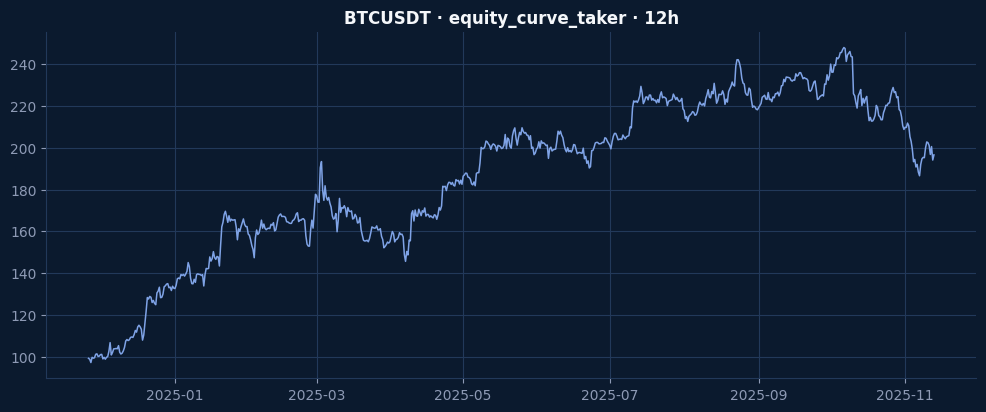

In [52]:
research.plot_static_timeseries(trades, sym, 'equity_curve_taker', time_interval)

### Calcular el Retorno Neto Total con Tamaño Compuesto

In [53]:
compound_total_net_return = trades['equity_curve_taker'][-1] / capital - 1
compound_total_net_return

0.9659142922670068

In [54]:
constant_sizing_net_return

0.7746020028486504

In [55]:
# el interés compuesto trabaja en los dos sentidos: al ganar se reinvierte la ganancia; al perder, cada operación siguiente es más pequeña
np.round(compound_total_net_return - constant_sizing_net_return, 2)

np.float64(0.19)

### Criterio de Kelly: ¿qué fracción del capital operar?

In [56]:
# la fracción que maximiza el crecimiento del capital es (retorno medio) / (varianza) de las operaciones, ya descontadas las comisiones
net_returns = trades['trade_log_return'] - trades['no_trades'] * taker_fee

kelly = net_returns.mean() / net_returns.var()
kelly

3.444017171579802

In [57]:
# Kelly supone que la ventaja estimada es exacta, y esta se midió dentro de muestra. En la práctica se usa la mitad o menos
kelly / 2

1.722008585789901

## Decisión Clave de Estrategia #3: Apalancamiento

In [58]:
# apalancarse es pedir dinero prestado para aumentar las ganancias

In [59]:
leverage = 4
leverage * capital

400

In [60]:
# en teoría, multiplicamos el tamaño de la operación para aumentar los retornos

In [61]:
# no estamos multiplicando el retorno de cada operación

In [62]:
# recuerda: amplifica TANTO las ganancias como las pérdidas, por eso es importante tener un valor esperado positivo

In [63]:
# el apalancamiento solo funciona con un modelo de Sharpe alto. Cuanto más se reduce el riesgo, menores son los drawdowns y más apalancamiento se puede usar

In [64]:
# decisión clave 3: ¿usamos apalancamiento? si es así, ¿cuánto? ¿cuál es el punto óptimo?

In [65]:
# no es una fórmula mágica para multiplicar ganancias: puede arruinarte con facilidad

In [66]:
trades = research.add_compounding_trades(trades, capital, leverage, maker_fee, taker_fee)
trades.select('datetime','dir_signal','entry_trade_value','exit_trade_value','trade_net_taker_pnl','equity_curve_gross','equity_curve_taker')

datetime,dir_signal,entry_trade_value,exit_trade_value,trade_net_taker_pnl,equity_curve_gross,equity_curve_taker
datetime[μs],f64,f64,f64,f64,f64,f64
2024-11-26 00:00:00,1.0,400.0,397.232012,-2.967988,97.232012,97.032012
2024-11-26 12:00:00,1.0,388.12805,386.454085,-1.673965,95.554597,95.358047
2024-11-27 00:00:00,-1.0,381.43219,375.706448,-6.107173,89.817054,89.250874
2024-11-27 12:00:00,1.0,357.003496,366.485753,9.125253,99.359464,98.376127
2024-11-28 00:00:00,1.0,393.50451,391.882571,-1.621938,97.721313,96.754189
…,…,…,…,…,…,…
2025-11-11 00:00:00,1.0,2117.354572,2103.165783,-14.188789,886.849127,515.149854
2025-11-11 12:00:00,1.0,2060.599415,2016.543361,-44.056055,811.005033,471.093799
2025-11-12 00:00:00,1.0,1884.375196,1920.489134,36.113938,873.176485,507.207737


In [67]:
trades['equity_curve_taker'][-1] / capital - 1

3.6452006482045665

## ¿Y si subimos a 8x de apalancamiento?

In [68]:
trades_8x = research.add_compounding_trades(trades, capital, 8, maker_fee, taker_fee)

In [69]:
trades_8x['equity_curve_taker'][-1] / capital - 1

-0.1464715231033098

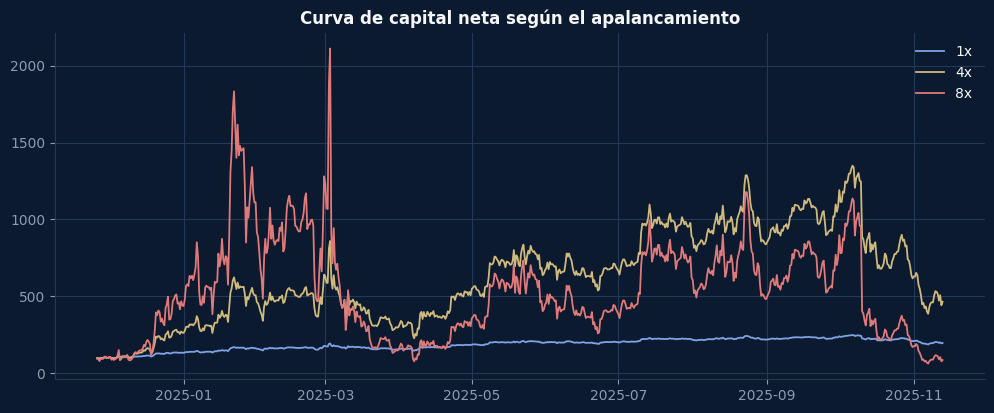

In [70]:
# el mismo modelo y las mismas señales con 1x, 4x y 8x
leverage_curves = trades.select('datetime').with_columns(
    research.add_compounding_trades(trades, capital, 1, maker_fee, taker_fee)['equity_curve_taker'].alias('1x'),
    trades['equity_curve_taker'].alias('4x'),
    trades_8x['equity_curve_taker'].alias('8x'),
)
research.plot_multiple_lines(leverage_curves, ['1x', '4x', '8x'], 'Curva de capital neta según el apalancamiento')

In [71]:
# el apalancamiento no cambia la ventaja del modelo: solo cambia el tamaño de lo que se gana o se pierde
# con 8x, muy por encima de Kelly, la misma estrategia que ganaba con 1x y 4x termina perdiendo

### La Tasa de Acierto no Cambió

In [72]:
trades.select((pl.col("trade_log_return") > 0).mean())

trade_log_return
f64
0.524823


### Considerar la Liquidación (el precio se mueve demasiado en contra)

In [73]:
# La liquidación es cuando lo perdemos todo. Con demasiado apalancamiento, un cambio pequeño de precio puede dejarnos en cero.

In [74]:
# el apalancamiento es un arma de doble filo: amplifica las ganancias, pero en exceso puede hacerte perder todo el dinero

In [75]:
# Capital = Margen de Mantenimiento
# el cálculo varía según el exchange

In [76]:
maintenance_margin = 0.005

def long_liquidation_price(p, l, mmr):
    return (p * l) / (l + 1 - mmr * l)

def short_liquidation_price(p, l, mmr):
    return (p * l) / (l - 1 + mmr * l)

### Cómo Afecta el Apalancamiento a las Posiciones Largas

In [77]:
long_liquidation_price(200, 2, maintenance_margin)

133.7792642140468

In [78]:
long_liquidation_price(200, 4, maintenance_margin)

160.64257028112448

In [79]:
long_liquidation_price(200, 10, maintenance_margin)

182.64840182648402

In [80]:
long_liquidation_price(200, 50, maintenance_margin)

197.04433497536945

### Cómo Afecta el Apalancamiento a las Posiciones Cortas

In [81]:
short_liquidation_price(200, 2, maintenance_margin)

396.03960396039605

In [82]:
short_liquidation_price(200, 4, maintenance_margin)

264.9006622516556

In [83]:
short_liquidation_price(200, 10, maintenance_margin)

220.99447513812152

In [84]:
short_liquidation_price(200, 60, maintenance_margin)

202.36087689713324

### Agregar los Precios de Liquidación

In [85]:
leverage

4

In [86]:
def add_liquidations(trades, leverage):
    return trades.with_columns(
        pl.when(pl.col("dir_signal") == 1)  # posición larga
          .then(long_liquidation_price(pl.col("open"), leverage, maintenance_margin))
          .otherwise(short_liquidation_price(pl.col("open"), leverage, maintenance_margin))  # posición corta
          .alias("liquidation_price"),
        # Peor precio de la vela según la dirección
        pl.when(pl.col("dir_signal") == 1).then(pl.col("low")).otherwise(pl.col("high")).alias("worst_price"),
    ).with_columns(
        # Indicador de liquidación: el peor precio de la vela alcanzó el precio de liquidación
        pl.when(pl.col("dir_signal") == 1)
          .then(pl.col("low") <= pl.col("liquidation_price"))
          .otherwise(pl.col("high") >= pl.col("liquidation_price"))
          .alias("liquidated")
    )

trades = add_liquidations(trades, leverage)
trades.select('datetime','open','low','high','close','dir_signal','worst_price','liquidation_price','liquidated')

datetime,open,low,high,close,dir_signal,worst_price,liquidation_price,liquidated
datetime[μs],f64,f64,f64,f64,f64,f64,f64,bool
2024-11-26 00:00:00,93064.0,91553.0,95064.0,92420.0,1.0,91553.0,74750.200803,false
2024-11-26 12:00:00,92420.0,90866.4,94745.2,92021.4,1.0,90866.4,74232.931727,false
2024-11-27 00:00:00,92021.5,91864.0,93939.0,93423.8,-1.0,93939.0,121882.781457,false
2024-11-27 12:00:00,93423.8,92903.4,97250.0,95905.2,1.0,92903.4,75039.196787,false
2024-11-28 00:00:00,95905.2,94700.1,96627.6,95509.9,1.0,94700.1,77032.289157,false
…,…,…,…,…,…,…,…,…
2025-11-11 00:00:00,105966.3,104685.3,107473.7,105256.2,1.0,104685.3,85113.493976,false
2025-11-11 12:00:00,105256.2,102400.0,105459.8,103005.8,1.0,102400.0,84543.13253,false
2025-11-12 00:00:00,103005.8,102629.5,105162.6,104979.9,1.0,102629.5,82735.582329,false


### Buscar Operaciones Liquidadas

In [87]:
trades.filter(pl.col("liquidated") == True).select('datetime','open','low','high','dir_signal','liquidation_price')

datetime,open,low,high,dir_signal,liquidation_price
datetime[μs],f64,f64,f64,f64,f64


In [88]:
# con 8x basta un movimiento de ~11% en contra dentro de una vela de 12 horas: pasó dos veces, incluso dentro de muestra
add_liquidations(trades, 8).filter(pl.col("liquidated") == True).select('datetime','open','low','high','dir_signal','liquidation_price')

datetime,open,low,high,dir_signal,liquidation_price
datetime[μs],f64,f64,f64,f64,f64
2024-12-05 12:00:00,102668.2,90200.0,103661.7,1.0,91668.035714
2025-10-10 12:00:00,121493.2,101516.5,122497.0,1.0,108476.071429


---
# L · Libre de sesgos
Un backtest puede mentir de tres formas. Antes de creerle a una curva de capital, hay que descartarlas.

### Sesgo de Anticipación (*look-ahead bias*)

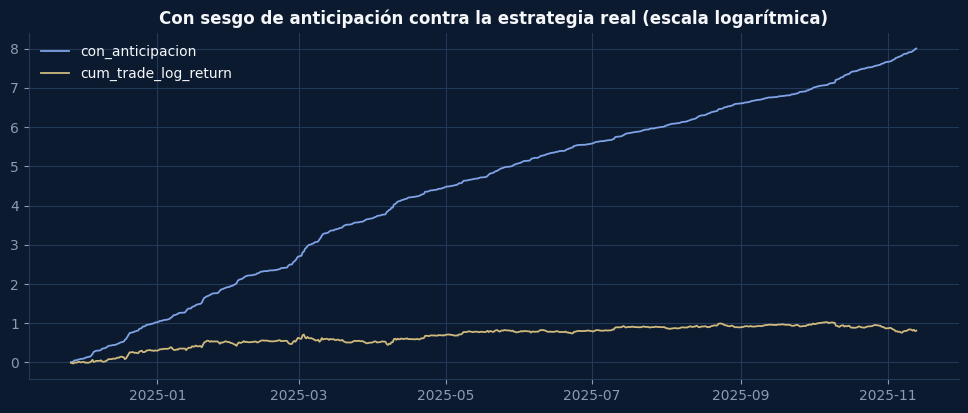

In [89]:
# si la señal usa el cierre de la misma vela que opera (un .shift() olvidado), el backtest ve el futuro y la curva es un milagro
leak = trades.with_columns(
    (pl.col('close_log_return').sign() * pl.col('close_log_return')).cum_sum().alias('con_anticipacion')
)
research.plot_multiple_lines(leak, ['con_anticipacion', 'cum_trade_log_return'], 'Con sesgo de anticipación contra la estrategia real (escala logarítmica)')

In [90]:
# multiplicar el capital por esto en un año no es una estrategia: es un error de programación
np.exp(leak['con_anticipacion'][-1])

np.float64(2981.5242175045723)

### Fuera de Muestra: Abrimos la Prueba

In [91]:
# hasta aquí todo se midió dentro de muestra: en el mismo tramo con el que elegimos el modelo
# la prueba no participó en nada. La abrimos una sola vez, con la misma estrategia y sin tocar ningún parámetro
test_trades = research.add_trade_log_returns(research.add_model_predictions(test_trades, model, features))
test_trades.select('datetime', 'close', 'y_hat', 'dir_signal', 'trade_log_return', 'no_trades')

datetime,close,y_hat,dir_signal,trade_log_return,no_trades
datetime[μs],f64,f64,f64,f64,f64
2025-11-13 12:00:00,99654.3,0.000478,1.0,-0.03205,1.0
2025-11-14 00:00:00,96134.6,0.000004,1.0,-0.035958,0.0
2025-11-14 12:00:00,94544.9,0.000722,1.0,-0.016674,0.0
2025-11-15 00:00:00,95657.3,-0.000094,-1.0,-0.011697,2.0
2025-11-15 12:00:00,95560.3,-0.000352,-1.0,0.001015,0.0
…,…,…,…,…,…
2026-10-29 12:00:00,77962.6,0.00046,1.0,-0.027432,0.0
2026-10-30 00:00:00,77345.9,0.000472,1.0,-0.007942,0.0
2026-10-30 12:00:00,77312.6,0.000111,1.0,-0.000431,0.0


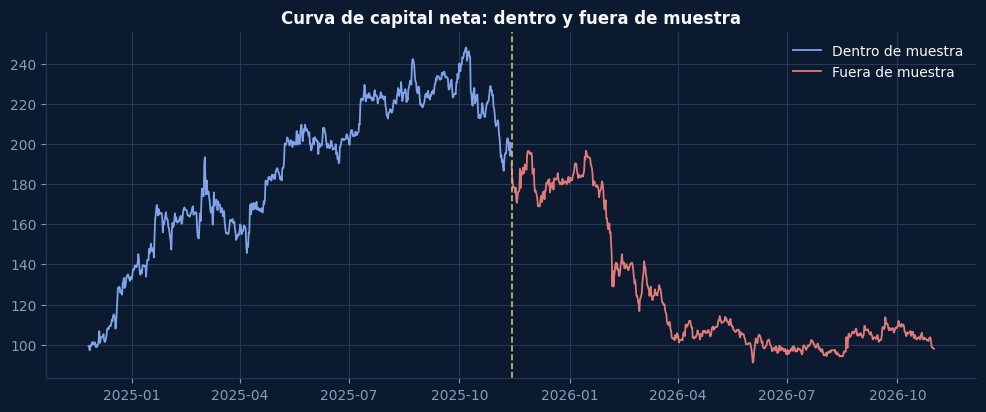

In [92]:
# la curva de capital neta (tamaño compuesto, 1x): lo que veíamos dentro de muestra y lo que pasó después
in_sample = research.add_compounding_trades(trades, capital, 1, maker_fee, taker_fee)
out_of_sample = research.add_compounding_trades(test_trades, in_sample['equity_curve_taker'][-1], 1, maker_fee, taker_fee)
research.plot_in_out_of_sample(in_sample, out_of_sample, 'equity_curve_taker', 'Curva de capital neta: dentro y fuera de muestra')

In [93]:
# retorno neto fuera de muestra empezando con el mismo capital, con 1x, 4x y 8x
[research.add_compounding_trades(test_trades, capital, l, maker_fee, taker_fee)['equity_curve_taker'][-1] / capital - 1 for l in (1, 4, 8)]

[-0.5016551005297087, -0.9782573035464116, -0.9999840013317727]

In [94]:
# y con 8x la cuenta también se liquida fuera de muestra
add_liquidations(test_trades, 8).filter(pl.col("liquidated") == True).select('datetime','open','low','high','dir_signal','liquidation_price')

datetime,open,low,high,dir_signal,liquidation_price
datetime[μs],f64,f64,f64,f64,f64
2026-02-05 12:00:00,70279.1,62233.3,70848.6,1.0,62749.196429


### Sesgo de Selección (*overfitting*)

In [95]:
# el modelo se eligió por ser el mejor de 14 dentro de muestra. ¿Rinde igual fuera de muestra, donde no hubo elección?
annualized_rate = research.sharpe_annualization_factor(time_interval)
pl.DataFrame([
    {'tramo': 'dentro de muestra', **research.eval_model_performance(trades['close_log_return'], trades['y_hat'], features, target, annualized_rate)},
    {'tramo': 'fuera de muestra', **research.eval_model_performance(test_trades['close_log_return'], test_trades['y_hat'], features, target, annualized_rate)},
]).select('tramo', 'no_trades', 'win_rate', 'ev', 'total_log_return', 'max_drawdown', 'sharpe')

tramo,no_trades,win_rate,ev,total_log_return,max_drawdown,sharpe
str,i64,f64,f64,f64,f64,f64
"""dentro de muestra""",705,0.524823,0.001152,0.812152,-0.270243,1.864097
"""fuera de muestra""",705,0.479433,-0.000794,-0.559736,-0.706332,-1.391664


In [96]:
# comprar y mantener en cada tramo: dentro de muestra el mercado terminó arriba; fuera de muestra, abajo
trades['close_log_return'].sum(), test_trades['close_log_return'].sum()

(0.10047021432553938, -0.2831881360882536)

### Prueba de Permutaciones: ¿la estrategia le gana al azar?

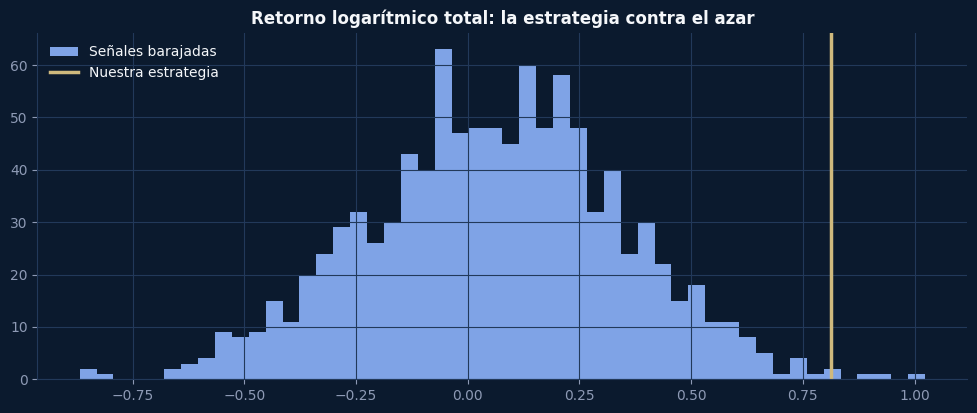

In [97]:
# barajamos las señales 1.000 veces: mismas velas, misma cantidad de largos y cortos, pero en momentos al azar
random_returns = research.permutation_test(trades, no_permutations=1000)
strategy_return = trades['trade_log_return'].sum()
research.plot_permutation_test(random_returns, strategy_return)

In [98]:
# valor p: fracción de las estrategias al azar que rinden igual o mejor que la nuestra (se busca menos de 0.05)
(random_returns >= strategy_return).mean()

np.float64(0.004)

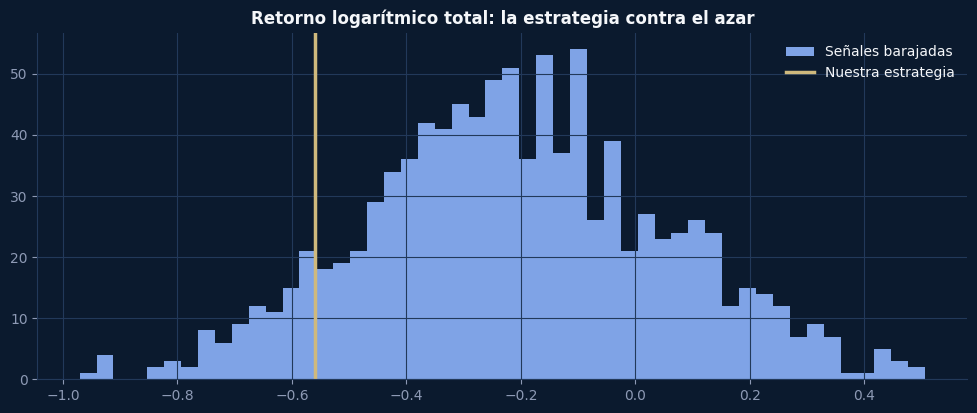

In [99]:
# dentro de muestra le gana al azar con claridad, pero el modelo se eligió justamente por ganar en ese tramo. La pregunta que vale es fuera de muestra
random_returns = research.permutation_test(test_trades, no_permutations=1000)
strategy_return = test_trades['trade_log_return'].sum()
research.plot_permutation_test(random_returns, strategy_return)

In [100]:
(random_returns >= strategy_return).mean()

np.float64(0.907)

### Hipótesis: ¿en qué tipo de mercado funciona?

In [101]:
# etiquetamos cada vela con lo que se sabía al abrirla: ¿el precio venía por encima o por debajo de su media de 100 velas (50 días)?
prev_close = pl.col('close').shift(1)
trend = ts.select('datetime', pl.when(prev_close > prev_close.rolling_mean(100)).then(pl.lit('alcista')).otherwise(pl.lit('bajista')).alias('tendencia'))

cols = ['datetime', 'close_log_return', 'dir_signal', 'trade_log_return']
both = pl.concat([
    trades.select(cols).with_columns(pl.lit('dentro de muestra').alias('tramo')),
    test_trades.select(cols).with_columns(pl.lit('fuera de muestra').alias('tramo')),
]).join(trend, on='datetime')

both.group_by('tramo', 'tendencia').agg(
    pl.len().alias('velas'),
    pl.col('close_log_return').sum().alias('comprar_y_mantener'),
    pl.col('trade_log_return').sum().alias('estrategia'),
    (pl.col('trade_log_return') > 0).mean().alias('acierto'),
).sort('tramo', 'tendencia')

tramo,tendencia,velas,comprar_y_mantener,estrategia,acierto
str,str,u32,f64,f64,f64
"""dentro de muestra""","""alcista""",400,0.011518,0.432695,0.515
"""dentro de muestra""","""bajista""",305,0.088952,0.379457,0.537705
"""fuera de muestra""","""alcista""",337,0.098033,-0.189869,0.465875
"""fuera de muestra""","""bajista""",368,-0.381221,-0.369867,0.491848


In [102]:
# hipótesis 1: el modelo compra después de las caídas (peso negativo de lag_1). Dentro de muestra las caídas rebotaban:
#              incluso en tendencia bajista comprar y mantener terminó en positivo. Fuera de muestra las caídas continuaron,
#              y en tendencia bajista la estrategia perdió casi lo mismo que el mercado

In [103]:
# ¿y por lado? velas en largo y en corto en cada tramo
both.group_by('tramo', pl.when(pl.col('dir_signal') == 1).then(pl.lit('largo')).otherwise(pl.lit('corto')).alias('lado')).agg(
    pl.len().alias('velas'),
    pl.col('trade_log_return').sum().alias('estrategia'),
    (pl.col('trade_log_return') > 0).mean().alias('acierto'),
).sort('tramo', 'lado')

tramo,lado,velas,estrategia,acierto
str,str,u32,f64,f64
"""dentro de muestra""","""corto""",81,0.355841,0.567901
"""dentro de muestra""","""largo""",624,0.456311,0.519231
"""fuera de muestra""","""corto""",80,-0.138274,0.4375
"""fuera de muestra""","""largo""",625,-0.421462,0.4848


In [104]:
# hipótesis 2: el sesgo positivo mantiene al modelo en largo casi 9 de cada 10 velas: necesita un mercado que no caiga de forma sostenida

In [105]:
# son hipótesis, no conclusiones: un año fuera de muestra son pocas velas para decidir
# la forma de comprobarlas es recoger datos nuevos sin arriesgar capital: desplegar el bot en una cuenta demo

### Veredicto

In [106]:
# 1. Simulación: dentro de muestra la estrategia casi duplica el capital después de comisiones
# 2. Tamaño: Kelly sugería apalancarse; con 8x incluso la curva ganadora termina perdiendo
# 3. Libre de sesgos: fuera de muestra el resultado no se repite: la estrategia pierde y no le gana al azar

# una curva bonita dentro de muestra es el punto de partida, no la prueba de una ventaja

In [107]:
# fin del notebook 2
# en el notebook 3 (E · Ejecución) programamos el sistema completo y lo conectamos a una cuenta demo de Binance
# la demo es parte del método: genera datos que ningún backtest ha visto y permite comprobar las hipótesis antes de arriesgar capital
# funcional no es lo mismo que rentable: el alfa es la pieza que se cambia

# temas que no cubrimos - esto es solo una base sobre la cual construir
# alpha decay (también llamado deriva del modelo) => el desempeño de la predicción se deteriora con el tiempo
# impacto de mercado => no operamos tamaños grandes => si lo hiciéramos, podríamos mover el mercado en nuestra contra
# comisiones de fondeo (funding) y reembolsos
# slippage => no siempre obtenemos el mejor precio; podemos ejecutar a precios peores que la punta del libro (mejor bid/ask)